# SDS 336 Group Project: Predicting Which Cases Get Cleared
**Dataset:** Austin Police Department crime reports (2.68M incidents, 2003–2026). Requires `data/processed/crime.parquet`, which `01_eda.ipynb` builds.

**Question:** At the moment a crime is reported, can we predict whether it will be cleared (solved)?

| Step | Choice | Why |
|---|---|---|
| Target | `cleared` = clearance status C (arrest) or O (exception) vs N | Binary outcome, so this is a **classification** problem |
| Scope | Victim-reported incidents, 2009–2025, excluding arrest-generated offenses | Clearance coding is unreliable before 2009 (01_eda); for offenses like DWI the report *is* the arrest, so there is nothing to predict |
| Features | Only information available at intake | Anything recorded later (clearance date, follow-up) would leak the answer |
| Split | Train 2009–2019 · validate 2020–2021 · test 2022–2025 | H3 showed clearance shifts over time; a model is used on *future* cases, so we test on the future |
| Models | Offense-only baseline, logistic regression, random forest, gradient boosting | One interpretable linear model and two tree ensembles that capture interactions |

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
                             precision_recall_curve)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CACHE = ROOT / "data" / "processed" / "crime.parquet"
FIG = ROOT / "figures" / "final"
assert CACHE.exists(), "Run notebooks/01_eda.ipynb first to build the parquet cache"
SEED = 336
rng = np.random.default_rng(SEED)

BLUE, ORANGE, AQUA, YELLOW, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#4a3aa7"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.figsize": (10, 4.8), "figure.dpi": 110, "savefig.dpi": 200,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titleweight": "bold",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 12, "axes.titlesize": 13,
    "legend.frameon": False,
})
pct = mtick.PercentFormatter(1, decimals=0)

def savefig(name):
    FIG.mkdir(parents=True, exist_ok=True)
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")

df = pd.read_parquet(CACHE)
print(f"{len(df):,} incidents loaded")

2,676,798 incidents loaded


## 1. Problem setup

### 1a. Target and time-based split

In [2]:
d = df[df["year"].between(2009, 2025) & df["clearance"].notna()
       & (df["report_lag_days"] >= 0) & df["occurred_date_time"].notna()].copy()
d["cleared"] = d["clearance"].ne("Not cleared").astype(int)
d["offense"] = d["highest_offense_description"].astype(str)
d["split"] = np.select([d["year"] <= 2019, d["year"] <= 2021], ["train", "val"], "test")
print(f"{len(d):,} incidents with a known clearance status, 2009-2025")

1,619,851 incidents with a known clearance status, 2009-2025


### 1b. Scope: drop arrest-generated offenses

For some offenses the report is written *because* someone was arrested (DWI, warrant arrests, drug possession). They are cleared 90–99% of the time by construction, so predicting them is trivial and would inflate every metric. We drop offenses whose **training-period (2009–2019)** clearance rate is at least 90%. The rule uses training data only, so the test set does not influence the scope.

In [3]:
train_rate = d[d["split"] == "train"].groupby("offense")["cleared"].agg(rate="mean", n="size")
arrest_generated = train_rate.query("rate >= 0.9 and n >= 100").sort_values("n", ascending=False)
print(f"{len(arrest_generated)} arrest-generated offenses removed, e.g.:")
print(arrest_generated.head(8).round(3).to_string())
before = len(d)
d = d[~d["offense"].isin(arrest_generated.index)].copy()
print(f"\nKept {len(d):,} of {before:,} incidents ({len(d)/before:.1%})")

39 arrest-generated offenses removed, e.g.:
                               rate      n
offense                                   
DWI                           0.983  34239
POSSESSION OF MARIJUANA       0.942  23071
WARRANT ARREST NON TRAFFIC    0.981  22357
CUSTODY ARREST TRAFFIC WARR   0.985  20462
POSS CONTROLLED SUB/NARCOTIC  0.949  16059
DWI 2ND                       0.986   5683
VOCO SOLICITATION PROHIBIT    0.988   4183
DWI  .15 BAC OR ABOVE         0.996   4080



Kept 1,423,384 of 1,619,851 incidents (87.9%)


In [4]:
summary = d.groupby("split", sort=False).agg(incidents=("cleared", "size"), cleared_rate=("cleared", "mean"),
                                             years=("year", lambda y: f"{y.min()}-{y.max()}"))
summary.loc[["train", "val", "test"]].assign(cleared_rate=lambda t: t["cleared_rate"].round(3))

,incidents,cleared_rate,years
split,,,
train,983211,0.196,2009-2019
val,156788,0.125,2020-2021
test,283385,0.163,2022-2025


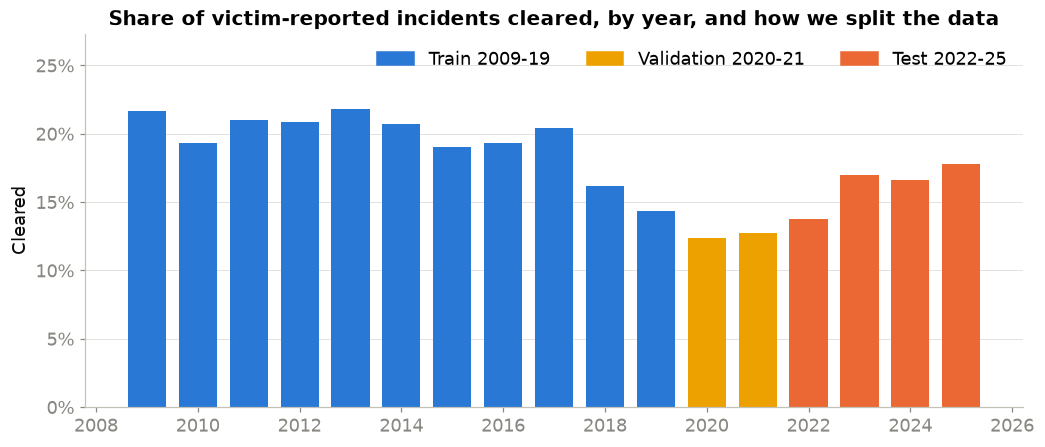

In [5]:
by_year = d.groupby("year")["cleared"].mean()
colors = {"train": BLUE, "val": YELLOW, "test": ORANGE}
split_of = d.groupby("year")["split"].first()
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.bar(by_year.index, by_year.values, color=[colors[split_of[y]] for y in by_year.index], width=0.75)
from matplotlib.patches import Patch
handles = [Patch(color=colors[k], label=l) for k, l in [("train", "Train 2009-19"), ("val", "Validation 2020-21"), ("test", "Test 2022-25")]]
ax.yaxis.set_major_formatter(pct); ax.grid(axis="x", visible=False)
ax.xaxis.set_major_locator(mtick.MultipleLocator(2)); ax.set_ylim(0, by_year.max() * 1.25)
ax.set(title="Share of victim-reported incidents cleared, by year, and how we split the data", ylabel="Cleared", xlabel="")
ax.legend(handles=handles, loc="upper right", ncol=3)
savefig("f1_split_timeline"); plt.show()

The test years have a **lower base rate** than training (the post-2017 drop from H3). A random split would hide this shift. A time-based split measures how the model would do on cases it actually has to predict.

### 1c. Features (known at intake only)

In [6]:
tr = d["split"] == "train"

# Offense: keep offenses with >= 1,000 training incidents, group the rest
keep_off = d.loc[tr, "offense"].value_counts().loc[lambda s: s >= 1000].index
d["offense_g"] = np.where(d["offense"].isin(keep_off), d["offense"], "OTHER")
loc = d["location_type"].astype(str).replace("nan", "UNKNOWN")
keep_loc = loc[tr].value_counts().head(25).index
d["location_g"] = np.where(loc.isin(keep_loc), loc, "OTHER")
sec = d["apd_sector"].astype(str)
keep_sec = sec[tr].value_counts().head(10).index
d["sector_g"] = np.where(sec.isin(keep_sec), sec, "OTHER")
d["district"] = d["council_district"].fillna(0).astype(int).astype(str)

occ = d["occurred_date_time"]
d["log_delay"] = np.log10(1 + d["report_lag_days"] * 24)      # log10(1 + hours)
d["on_hour"] = occ.dt.minute.eq(0).astype(int)                # H2: rounded time
d["first_of_month"] = occ.dt.day.eq(1).astype(int)            # H4: placeholder date
d["hour"] = occ.dt.hour.astype(int)
d["dow"] = occ.dt.dayofweek.astype(int).astype(str)
d["month"] = occ.dt.month.astype(int).astype(str)
d["family_violence"] = d["family_violence"].astype(int)
print(f"{d['offense_g'].nunique()} offense groups, {d['location_g'].nunique()} location groups, "
      f"{d['sector_g'].nunique()} sectors, {d['district'].nunique()} districts")

77 offense groups, 26 location groups, 11 sectors, 11 districts


**Neighborhood profile (from H5).** For each census block group, we describe its crime mix (shares of the 15 most common offenses, plus night, weekend and family-violence shares) using **2009–2019 incidents only**, then project it onto two principal components. This is unsupervised (it never sees clearance), so it cannot leak the target. Block groups with too few incidents get 0 (the average) and a flag.

In [7]:
hist = df[df["year"].between(2009, 2019) & df["census_block_group"].notna()]
off_h = hist["highest_offense_description"].astype(str)
top15 = off_h.value_counts().head(15).index
prof = pd.crosstab(hist["census_block_group"], np.where(off_h.isin(top15), off_h, "OTHER"), normalize="index")
g = hist.groupby("census_block_group")
prof["NIGHT"] = g["hour"].apply(lambda h: (h.ge(22) | h.lt(4)).mean())
prof["WEEKEND"] = g["dow"].apply(lambda s: s.ge(5).mean())
prof["FAMILY VIOLENCE"] = g["family_violence"].mean()
prof = prof[g.size().reindex(prof.index) >= 200]
scaler = StandardScaler().fit(prof)
pca = PCA(2, random_state=SEED).fit(scaler.transform(prof))
pcs = pd.DataFrame(pca.transform(scaler.transform(prof)), index=prof.index, columns=["bg_pc1", "bg_pc2"])
load1 = pd.Series(pca.components_[0], index=prof.columns)
if load1["FAMILY DISTURBANCE"] < 0:          # orient PC1 so that + = more domestic
    pcs["bg_pc1"] *= -1; load1 *= -1
print(f"{len(prof)} block groups profiled; PC1 explains {pca.explained_variance_ratio_[0]:.0%} of variance")
print("PC1 (+) domestic:", ", ".join(load1.sort_values().tail(3).index.str.title()))
print("PC1 (-) commercial:", ", ".join(load1.sort_values().head(3).index.str.title()))

d = d.join(pcs, on="census_block_group")
d["bg_known"] = d["bg_pc1"].notna().astype(int)
d[["bg_pc1", "bg_pc2"]] = d[["bg_pc1", "bg_pc2"]].fillna(0.0)

617 block groups profiled; PC1 explains 25% of variance
PC1 (+) domestic: Assault With Injury-Fam/Dating Vio, Family Violence, Family Disturbance
PC1 (-) commercial: Warrant Arrest Non Traffic, Theft, Dwi


In [8]:
CAT = ["offense_g", "location_g", "sector_g", "district", "dow", "month"]
NUM = ["log_delay", "on_hour", "first_of_month", "hour", "family_violence", "bg_pc1", "bg_pc2", "bg_known"]
FEATURES = CAT + NUM
feature_table = pd.DataFrame({
    "feature": FEATURES,
    "type": ["categorical"] * len(CAT) + ["numeric/binary"] * len(NUM),
    "source": ["offense description", "location type", "APD sector", "council district", "day of week", "month",
               "report delay, log10(1+hours) [H1]", "time rounded to :00 [H2]", "date on the 1st [H4]",
               "hour occurred", "family-violence flag", "block-group crime mix PC1 [H5]", "PC2", "block group profiled"],
})
feature_table

,feature,type,source
0,offense_g,categorical,offense description
1,location_g,categorical,location type
2,sector_g,categorical,APD sector
3,district,categorical,council district
4,dow,categorical,day of week
5,month,categorical,month
6,log_delay,numeric/binary,"report delay, log10(1+hours) [H1]"
7,on_hour,numeric/binary,time rounded to :00 [H2]
8,first_of_month,numeric/binary,date on the 1st [H4]
9,hour,numeric/binary,hour occurred


In [9]:
train = d[d["split"] == "train"]; val = d[d["split"] == "val"]; test = d[d["split"] == "test"]
trainval = d[d["split"] != "test"]
# Tuning runs on a 400k sample of training years (the full validation set scores each config)
tune = train.sample(400_000, random_state=SEED)
y = lambda frame: frame["cleared"].to_numpy()
print(f"train {len(train):,} · tune sample {len(tune):,} · val {len(val):,} · test {len(test):,}")

train 983,211 · tune sample 400,000 · val 156,788 · test 283,385


## 2. Modeling

### Evaluation metrics, chosen for the use case
The realistic use is **triage**: ranking new cases so investigators spend limited time where it is most likely to pay off. That drives the metrics:

- **Average precision (PR-AUC), primary:** only about 1 in 5 cases is cleared. PR-AUC focuses on how well the model ranks the cleared minority, which is what triage needs. ROC-AUC can look good just by ranking the many easy negatives.
- **ROC-AUC:** reported for comparison with other work.
- **Brier score and calibration:** if predicted probabilities are shown to investigators or victims ("about 10% chance this is solved"), they need to mean what they say.
- **Capture in the top 20%:** of all cases that end up cleared, what share is in the 20% of cases the model ranks highest. This is the operational number for a triage queue.
- **Within-offense AUC:** the baseline already knows the offense. This measures whether the model ranks cases *within the same offense*, which is the information an investigator doesn't already have.

In [10]:
def top_capture(y_true, p, frac=0.2):
    k = int(len(p) * frac)
    top = np.argsort(-p)[:k]
    return y_true[top].sum() / y_true.sum()

def within_offense_auc(frame, p, min_each=100):
    out = []
    for off, idx in frame.groupby("offense_g").indices.items():
        yt = frame["cleared"].to_numpy()[idx]
        if yt.sum() >= min_each and (len(yt) - yt.sum()) >= min_each:
            out.append((roc_auc_score(yt, p[idx]), len(idx)))
    a = np.array(out)
    return np.average(a[:, 0], weights=a[:, 1])

def evaluate(frame, p):
    yt = y(frame)
    return {"PR-AUC": average_precision_score(yt, p), "ROC-AUC": roc_auc_score(yt, p),
            "Brier": brier_score_loss(yt, p), "Top-20% capture": top_capture(yt, p),
            "Within-offense AUC": within_offense_auc(frame, p)}

### 2a. Baseline: offense-only lookup
Predict each case's training-period clearance rate for its offense (lightly smoothed). Any model has to beat "just knowing the crime type."

In [11]:
def offense_lookup(fit_frame, alpha=20):
    prior = fit_frame["cleared"].mean()
    s = fit_frame.groupby("offense_g")["cleared"].agg(["sum", "count"])
    rate = (s["sum"] + alpha * prior) / (s["count"] + alpha)
    return lambda frame: frame["offense_g"].map(rate).fillna(prior).to_numpy()

baseline = offense_lookup(train)
val_results = {"Offense-only baseline": evaluate(val, baseline(val))}
pd.DataFrame(val_results).T.round(3)

,PR-AUC,ROC-AUC,Brier,Top-20% capture,Within-offense AUC
Offense-only baseline,0.42,0.817,0.103,0.575,0.5


### 2b. Logistic regression
A linear model on one-hot categories and standardized numeric features. It is interpretable (odds ratios) and a strong benchmark. We tune the L2 regularization strength **C** on the validation years.

In [12]:
def lr_pipeline(C):
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), CAT + ["hour"]),
        ("num", StandardScaler(), [c for c in NUM if c != "hour"]),
    ])
    return make_pipeline(pre, LogisticRegression(C=C, max_iter=3000))

lr_grid = {}
for C in [0.01, 0.1, 1.0, 10.0]:
    t = time.time()
    m = lr_pipeline(C).fit(tune[FEATURES], y(tune))
    lr_grid[C] = average_precision_score(y(val), m.predict_proba(val[FEATURES])[:, 1])
    print(f"C={C:<5} val PR-AUC={lr_grid[C]:.4f}  ({time.time()-t:.0f}s)")
best_C = max(lr_grid, key=lr_grid.get)
lr_tuned = lr_pipeline(best_C).fit(tune[FEATURES], y(tune))
val_results["Logistic regression"] = evaluate(val, lr_tuned.predict_proba(val[FEATURES])[:, 1])
print("best C:", best_C)

C=0.01  val PR-AUC=0.4800  (2s)


C=0.1   val PR-AUC=0.4890  (2s)


C=1.0   val PR-AUC=0.4896  (2s)


C=10.0  val PR-AUC=0.4898  (2s)


best C: 10.0


### 2c. Random forest
Bagged decision trees capture interactions (for example, delay mattering more for theft than for assault) without us specifying them. Categories are ordinal-encoded, which trees can split on. We tune **tree depth** and **minimum leaf size**, the two settings that control how much each tree overfits.

In [13]:
ord_enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit(train[CAT])
def tree_X(frame):
    X = frame[FEATURES].copy()
    X[CAT] = ord_enc.transform(frame[CAT]).astype(int)
    return X

Xtune, Xval = tree_X(tune), tree_X(val)
rf_grid = {}
for depth in [12, 24, None]:
    for leaf in [2, 5, 50]:
        t = time.time()
        m = RandomForestClassifier(n_estimators=150, max_depth=depth, min_samples_leaf=leaf,
                                   max_features="sqrt", n_jobs=-1, random_state=SEED).fit(Xtune, y(tune))
        rf_grid[(depth, leaf)] = average_precision_score(y(val), m.predict_proba(Xval)[:, 1])
        print(f"depth={str(depth):<4} min_leaf={leaf:<3} val PR-AUC={rf_grid[(depth, leaf)]:.4f}  ({time.time()-t:.0f}s)")
best_rf = max(rf_grid, key=rf_grid.get)
rf_tuned = RandomForestClassifier(n_estimators=150, max_depth=best_rf[0], min_samples_leaf=best_rf[1],
                                  max_features="sqrt", n_jobs=-1, random_state=SEED).fit(Xtune, y(tune))
val_results["Random forest"] = evaluate(val, rf_tuned.predict_proba(Xval)[:, 1])
print("best (depth, min_leaf):", best_rf)

depth=12   min_leaf=2   val PR-AUC=0.4916  (9s)


depth=12   min_leaf=5   val PR-AUC=0.4918  (9s)


depth=12   min_leaf=50  val PR-AUC=0.4843  (10s)


depth=24   min_leaf=2   val PR-AUC=0.5070  (14s)


depth=24   min_leaf=5   val PR-AUC=0.5075  (14s)


depth=24   min_leaf=50  val PR-AUC=0.4932  (11s)


depth=None min_leaf=2   val PR-AUC=0.5039  (14s)


depth=None min_leaf=5   val PR-AUC=0.5077  (14s)


depth=None min_leaf=50  val PR-AUC=0.4928  (13s)


best (depth, min_leaf): (None, 5)


### 2d. Gradient boosting
Boosted trees fit the remaining errors sequentially and usually do best on tabular data. sklearn's histogram GBM handles categories natively. We tune the **learning rate** and **leaves per tree**. The number of trees is set by **early stopping** on a held-out 10% of the training sample, so we don't have to grid-search it.

In [14]:
cat_mask = [c in CAT for c in FEATURES]
def gbm(lr, leaves):
    return HistGradientBoostingClassifier(learning_rate=lr, max_leaf_nodes=leaves, min_samples_leaf=100,
                                          l2_regularization=1.0, max_iter=2500, early_stopping=True,
                                          validation_fraction=0.1, n_iter_no_change=30,
                                          categorical_features=cat_mask, random_state=SEED)
gb_grid = {}
for lr in [0.05, 0.15]:
    for leaves in [31, 127]:
        t = time.time()
        m = gbm(lr, leaves).fit(Xtune, y(tune))
        gb_grid[(lr, leaves)] = average_precision_score(y(val), m.predict_proba(Xval)[:, 1])
        print(f"lr={lr:<5} leaves={leaves:<4} trees={m.n_iter_:<4} val PR-AUC={gb_grid[(lr, leaves)]:.4f}  ({time.time()-t:.0f}s)")
best_gb = max(gb_grid, key=gb_grid.get)
gb_tuned = gbm(*best_gb).fit(Xtune, y(tune))
val_results["Gradient boosting"] = evaluate(val, gb_tuned.predict_proba(Xval)[:, 1])
print("best (learning rate, leaves):", best_gb)

lr=0.05  leaves=31   trees=750  val PR-AUC=0.5334  (14s)


lr=0.05  leaves=127  trees=230  val PR-AUC=0.5331  (13s)


lr=0.15  leaves=31   trees=201  val PR-AUC=0.5324  (4s)


lr=0.15  leaves=127  trees=91   val PR-AUC=0.5301  (6s)


best (learning rate, leaves): (0.05, 31)


In [15]:
val_table = pd.DataFrame(val_results).T
print("Validation years (2020-2021), models fit on the 400k training sample:")
val_table.round(3)

Validation years (2020-2021), models fit on the 400k training sample:


,PR-AUC,ROC-AUC,Brier,Top-20% capture,Within-offense AUC
Offense-only baseline,0.420,0.817,0.103,0.575,0.500
Logistic regression,0.490,0.857,0.090,0.679,0.722
Random forest,0.508,0.871,0.084,0.689,0.752
Gradient boosting,0.533,0.880,0.083,0.714,0.755


## 3. Evaluation on the held-out test years (2022–2025)

We refit each tuned model on **all of 2009–2021** (train + validation), then score the test years once. The random forest is refit on a 600k sample of 2009–2021, because a full fit doesn't fit in memory on a laptop. Logistic regression and gradient boosting use all rows.

In [16]:
t = time.time()
final = {"Offense-only baseline": offense_lookup(trainval)}
lr_final = lr_pipeline(best_C).fit(trainval[FEATURES], y(trainval))
final["Logistic regression"] = lambda f: lr_final.predict_proba(f[FEATURES])[:, 1]
rf_sample = trainval.sample(600_000, random_state=SEED)
rf_final = RandomForestClassifier(n_estimators=150, max_depth=best_rf[0], min_samples_leaf=best_rf[1],
                                  max_features="sqrt", n_jobs=-1, random_state=SEED).fit(tree_X(rf_sample), y(rf_sample))
final["Random forest"] = lambda f: rf_final.predict_proba(tree_X(f))[:, 1]
gb_final = gbm(*best_gb).fit(tree_X(trainval), y(trainval))
final["Gradient boosting"] = lambda f: gb_final.predict_proba(tree_X(f))[:, 1]
print(f"refit in {time.time()-t:.0f}s; GBM used {gb_final.n_iter_} trees")

test_pred = {name: f(test) for name, f in final.items()}
del rf_final, rf_tuned, final   # fully grown forests are large; free memory before interpretation
import gc; gc.collect()
test_table = pd.DataFrame({name: evaluate(test, p) for name, p in test_pred.items()}).T
test_table.round(3)

refit in 77s; GBM used 1315 trees


,PR-AUC,ROC-AUC,Brier,Top-20% capture,Within-offense AUC
Offense-only baseline,0.446,0.817,0.111,0.562,0.500
Logistic regression,0.521,0.865,0.100,0.649,0.727
Random forest,0.552,0.869,0.097,0.646,0.731
Gradient boosting,0.565,0.879,0.094,0.671,0.735


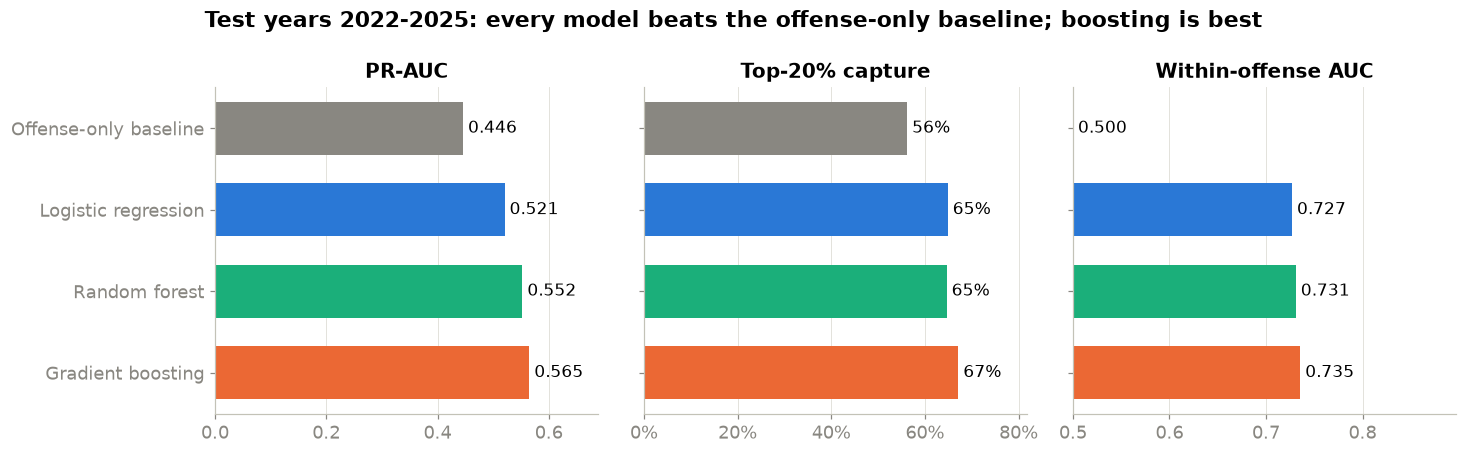

In [17]:
MODEL_COLORS = {"Offense-only baseline": MUTED, "Logistic regression": BLUE,
                "Random forest": AQUA, "Gradient boosting": ORANGE}
order = list(MODEL_COLORS)
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2), sharey=True)
for ax, metric in zip(axes, ["PR-AUC", "Top-20% capture", "Within-offense AUC"]):
    vals = test_table.loc[order, metric]
    ax.barh(range(len(order)), vals, color=[MODEL_COLORS[m] for m in order], height=0.65)
    for i, v in enumerate(vals):
        ax.text(v, i, f" {v:.3f}" if metric != "Top-20% capture" else f" {v:.0%}", va="center", fontsize=11)
    ax.set_title(metric); ax.grid(axis="y", visible=False)
    ax.set_xlim(0.5 if metric == "Within-offense AUC" else 0, max(vals) * 1.22)
    if metric == "Top-20% capture": ax.xaxis.set_major_formatter(pct)
axes[0].set_yticks(range(len(order))); axes[0].set_yticklabels(order); axes[0].invert_yaxis()
fig.suptitle("Test years 2022-2025: every model beats the offense-only baseline; boosting is best", fontweight="bold")
fig.tight_layout(); savefig("f2_model_comparison"); plt.show()

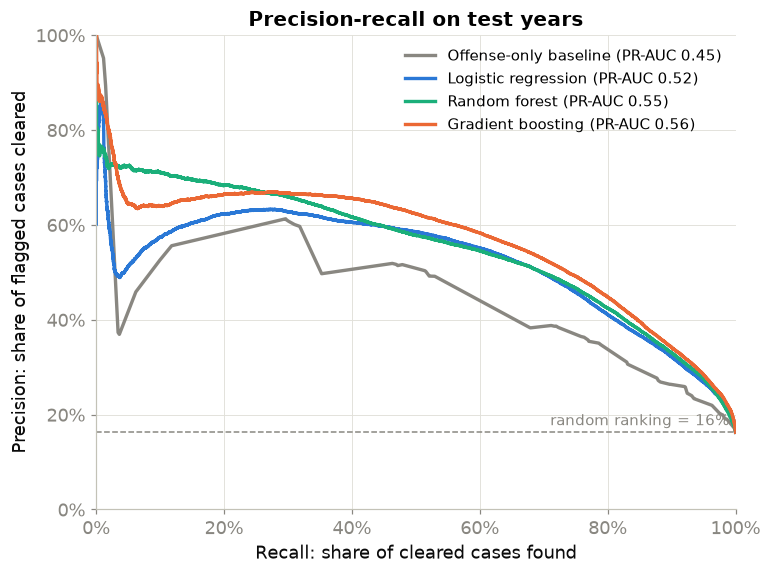

In [18]:
fig, ax = plt.subplots(figsize=(7.5, 5.6))
base = test["cleared"].mean()
for name in order:
    prec, rec, _ = precision_recall_curve(y(test), test_pred[name])
    ax.plot(rec, prec, color=MODEL_COLORS[name], lw=2.2, label=f"{name} (PR-AUC {test_table.loc[name, 'PR-AUC']:.2f})")
ax.axhline(base, color=MUTED, ls="--", lw=1)
ax.text(0.99, base + 0.015, f"random ranking = {base:.0%}", ha="right", fontsize=10, color=MUTED)
ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Recall: share of cleared cases found",
       ylabel="Precision: share of flagged cases cleared", title="Precision-recall on test years")
ax.legend(loc="upper right", fontsize=10)
savefig("f3_pr_curves"); plt.show()

### 3b. Is the time-based split necessary? Random split vs. future years
If we had shuffled all years together, how optimistic would our estimate be? We fit the best model on a random 80% of 2009–2025 (same sample size as a fair comparison) and score the random 20%, then compare with the true future test.

In [19]:
pool = d.sample(len(trainval) if len(trainval) < 1_400_000 else 1_400_000, random_state=SEED)
cut = int(len(pool) * 0.8)
rs_train, rs_test = pool.iloc[:cut], pool.iloc[cut:]
rs_model = gbm(*best_gb).fit(tree_X(rs_train), y(rs_train))
rs_p = rs_model.predict_proba(tree_X(rs_test))[:, 1]
split_cmp = pd.DataFrame({
    "Random 80/20 split": [average_precision_score(y(rs_test), rs_p), roc_auc_score(y(rs_test), rs_p), rs_test["cleared"].mean()],
    "Train past, test 2022-25": [test_table.loc["Gradient boosting", "PR-AUC"], test_table.loc["Gradient boosting", "ROC-AUC"], test["cleared"].mean()],
}, index=["PR-AUC", "ROC-AUC", "Base rate"]).T
split_cmp.round(3)

,PR-AUC,ROC-AUC,Base rate
Random 80/20 split,0.697,0.895,0.182
"Train past, test 2022-25",0.565,0.879,0.163


In [20]:
yr = test.assign(p=test_pred["Gradient boosting"]).groupby("year").apply(
    lambda g: pd.Series({"PR-AUC": average_precision_score(g["cleared"], g["p"]),
                         "Base rate": g["cleared"].mean(), "Mean predicted": g["p"].mean(), "n": len(g)}))
yr.round(3)

,PR-AUC,Base rate,Mean predicted,n
year,,,,
2022,0.561,0.137,0.177,71987.0
2023,0.578,0.170,0.187,69536.0
2024,0.578,0.166,0.188,69876.0
2025,0.551,0.178,0.195,71986.0


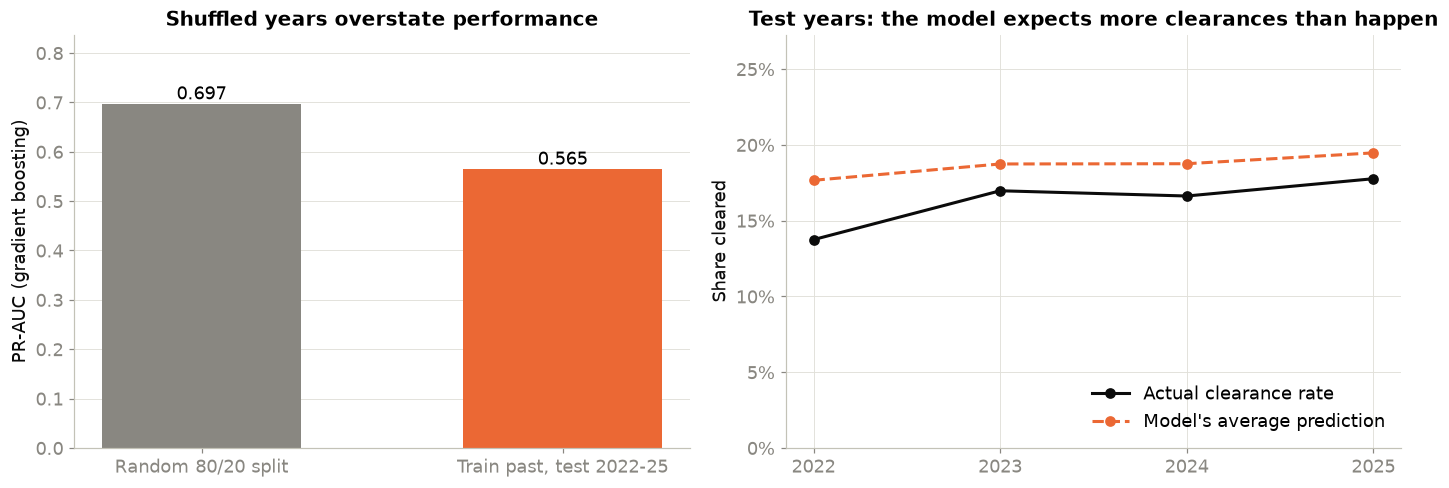

In [21]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6))
cmp_ = split_cmp["PR-AUC"]
a1.bar(range(2), cmp_.values, color=[MUTED, ORANGE], width=0.55)
a1.set_xticks(range(2)); a1.set_xticklabels(cmp_.index)
for i, v in enumerate(cmp_.values): a1.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=12)
a1.set(title="Shuffled years overstate performance", ylabel="PR-AUC (gradient boosting)"); a1.grid(axis="x", visible=False)
a1.set_ylim(0, cmp_.max() * 1.2)

a2.plot(yr.index, yr["Base rate"], color=INK, lw=2, marker="o", label="Actual clearance rate")
a2.plot(yr.index, yr["Mean predicted"], color=ORANGE, lw=2, marker="o", ls="--", label="Model's average prediction")
a2.yaxis.set_major_formatter(pct); a2.set_ylim(0, max(yr["Mean predicted"].max(), yr["Base rate"].max()) * 1.4)
a2.set_xticks(yr.index); a2.legend(loc="lower right")
a2.set(title="Test years: the model expects more clearances than happen", ylabel="Share cleared")
fig.tight_layout(); savefig("f4_split_and_drift"); plt.show()

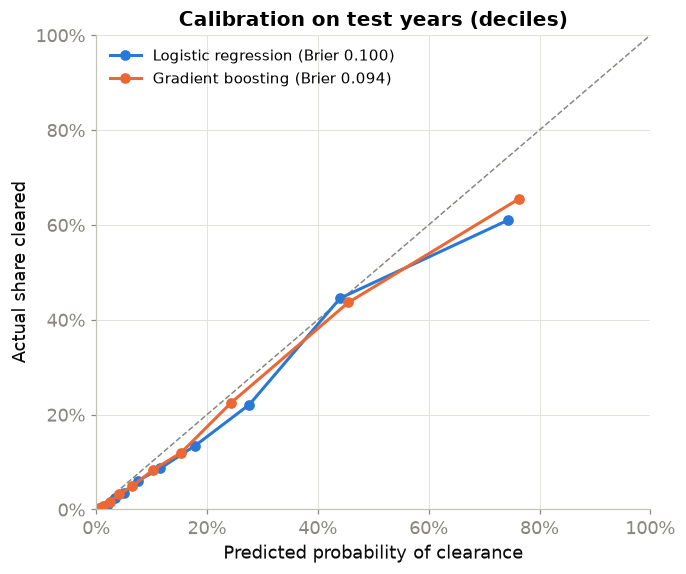

In [22]:
fig, ax = plt.subplots(figsize=(6.5, 5.6))
ax.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1)
for name in ["Logistic regression", "Gradient boosting"]:
    frac_pos, mean_pred = calibration_curve(y(test), test_pred[name], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", lw=2, color=MODEL_COLORS[name],
            label=f"{name} (Brier {test_table.loc[name, 'Brier']:.3f})")
ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
ax.set(xlabel="Predicted probability of clearance", ylabel="Actual share cleared",
       title="Calibration on test years (deciles)", xlim=(0, 1), ylim=(0, 1))
ax.legend(loc="upper left", fontsize=10)
savefig("f5_calibration"); plt.show()

### What the evaluation shows
- **Gradient boosting is best on every metric**, and the ranking of models is the same on validation and test years, so the choice isn't luck. On the test years it reaches PR-AUC **0.565**, against 0.446 for the offense-only lookup and 0.163 for random ranking.
- **Triage value:** the 20% of cases the model ranks highest contain **67%** of all cases that end up cleared, against 56% for the offense lookup. A detective working from the model's top fifth would see about one in five more of the solvable cases.
- **It adds what investigators don't already know:** within a single offense, the model ranks cases at an AUC of **0.735**. The offense lookup can't do that (0.5 by construction).
- **Trees beat logistic regression by 0.03–0.04 PR-AUC.** The gain comes from interactions. For example, delay matters differently for property and violent crime (Section 4), and a linear model can't express that without hand-built interaction terms.
- **A random split would have overstated performance:** PR-AUC is 0.697 when years are shuffled, against 0.565 on true future years. Part of the gap is the base rate (18.2% vs 16.3%), but the model still looks better shuffled relative to the base rate (3.8× vs 3.5×) and in ROC-AUC (0.895 vs 0.879). A department using the model would get the time-split number.
- **Ranking holds up, probabilities drift:** PR-AUC stays between 0.55 and 0.58 in every test year, but the model's average prediction runs 1.7–4 points above the actual clearance rate (worst in 2022). It learned from years when more cases were cleared. Before showing probabilities to anyone, they should be recalibrated on the most recent year.

## 4. Interpretation

We use three methods, each chosen to answer a question a stakeholder would actually ask:

| Stakeholder question | Method | Why this method |
|---|---|---|
| "Holding the crime fixed, does reporting late or having no witness hurt the odds?" | **Logistic-regression odds ratios** | Coefficients are direct, additive effects *conditional on offense*: exactly the "same crime, different circumstances" comparison. |
| "What information does the best model actually rely on?" | **Grouped permutation importance (gradient boosting, test years)** | Model-agnostic, measured on unseen future data, and in units of the metric we care about (PR-AUC). We permute each *raw* feature, so all of an offense's one-hot columns move together. |
| "Is there a window after which reporting stops helping?" | **Partial dependence of report delay (gradient boosting)** | Odds ratios assume a straight line in log-delay. PDP shows the actual shape, and we split it by crime type because H1 showed the effect differs. |

We deliberately do **not** use SHAP-style per-case explanations. Nobody in this setting acts on one prediction's breakdown, and a per-case explanation risks being read as a statement about an individual victim's case.

In [23]:
ohe_names = lr_final[0].get_feature_names_out()
coefs = pd.Series(lr_final[-1].coef_[0], index=ohe_names)
sd = trainval[["log_delay", "bg_pc1", "bg_pc2"]].std()
rows = {
    "Report delay: 10× longer": np.exp(coefs["num__log_delay"] / sd["log_delay"]),
    "Time rounded to :00 (no witness)": np.exp(coefs["num__on_hour"] / trainval["on_hour"].std()),
    "Date on the 1st (placeholder)": np.exp(coefs["num__first_of_month"] / trainval["first_of_month"].std()),
    "Family-violence flag": np.exp(coefs["num__family_violence"] / trainval["family_violence"].std()),
    "Neighborhood: +1 SD more domestic (PC1)": np.exp(coefs["num__bg_pc1"] / sd["bg_pc1"] * pcs["bg_pc1"].std()),
}
odds = pd.Series(rows).sort_values()
odds.round(3)

Report delay: 10× longer                   0.600
Time rounded to :00 (no witness)           0.688
Neighborhood: +1 SD more domestic (PC1)    0.917
Date on the 1st (placeholder)              1.164
Family-violence flag                       2.886
dtype: float64

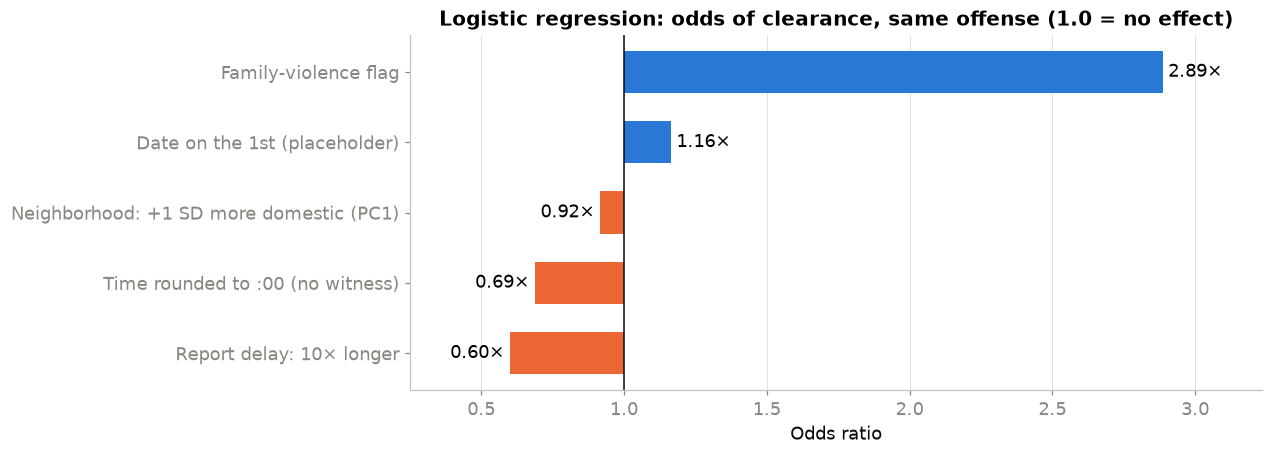

In [24]:
fig, ax = plt.subplots(figsize=(10, 4.2))
cols = [ORANGE if v < 1 else BLUE for v in odds.values]
ax.barh(range(len(odds)), odds.values - 1, left=1, color=cols, height=0.6)
ax.axvline(1, color=INK, lw=1)
for i, v in enumerate(odds.values):
    ax.text(v + (0.02 if v >= 1 else -0.02), i, f"{v:.2f}×", va="center", ha="left" if v >= 1 else "right", fontsize=12)
ax.set_yticks(range(len(odds))); ax.set_yticklabels(odds.index); ax.grid(axis="y", visible=False)
ax.set_xlim(min(odds.min(), 1) - 0.35, max(odds.max(), 1) + 0.35)
ax.set(title="Logistic regression: odds of clearance, same offense (1.0 = no effect)", xlabel="Odds ratio")
savefig("f6_odds_ratios"); plt.show()

In [25]:
imp_sample = test.sample(120_000, random_state=SEED)
Xi = tree_X(imp_sample)
pi = permutation_importance(gb_final, Xi, y(imp_sample), scoring="average_precision",
                            n_repeats=5, random_state=SEED, n_jobs=2)
NICE = {"offense_g": "Offense", "log_delay": "Report delay", "location_g": "Location type",
        "family_violence": "Family-violence flag", "on_hour": "Time rounded to :00", "hour": "Hour of day",
        "sector_g": "APD sector", "bg_pc1": "Neighborhood PC1", "bg_pc2": "Neighborhood PC2",
        "district": "Council district", "dow": "Day of week", "month": "Month",
        "first_of_month": "Date on the 1st", "bg_known": "Block group profiled"}
imp = pd.DataFrame({"drop": pi.importances_mean, "sd": pi.importances_std}, index=[NICE[c] for c in FEATURES]).sort_values("drop")
imp.round(4).iloc[::-1]

,drop,sd
Offense,0.2774,0.0013
Report delay,0.0951,0.0007
Family-violence flag,0.0352,0.0005
Location type,0.0301,0.0017
Neighborhood PC1,0.0105,0.0004
Hour of day,0.0085,0.0006
Time rounded to :00,0.0083,0.0005
Neighborhood PC2,0.0042,0.0004
APD sector,0.0032,0.0003
Council district,0.0026,0.0003


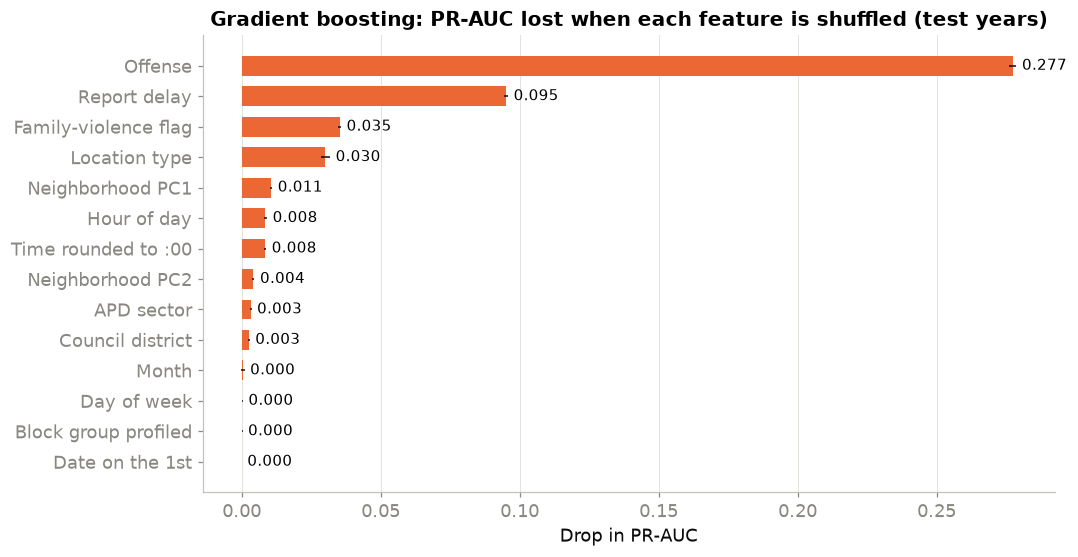

In [26]:
fig, ax = plt.subplots(figsize=(10, 5.4))
ax.barh(imp.index, imp["drop"], xerr=imp["sd"], color=ORANGE, height=0.65, error_kw={"ecolor": INK, "lw": 1})
for i, v in enumerate(imp["drop"]):
    ax.text(v + imp["sd"].iloc[i] + 0.002, i, f"{v:.3f}", va="center", fontsize=10)
ax.grid(axis="y", visible=False)
ax.set(title="Gradient boosting: PR-AUC lost when each feature is shuffled (test years)", xlabel="Drop in PR-AUC")
savefig("f7_permutation_importance"); plt.show()

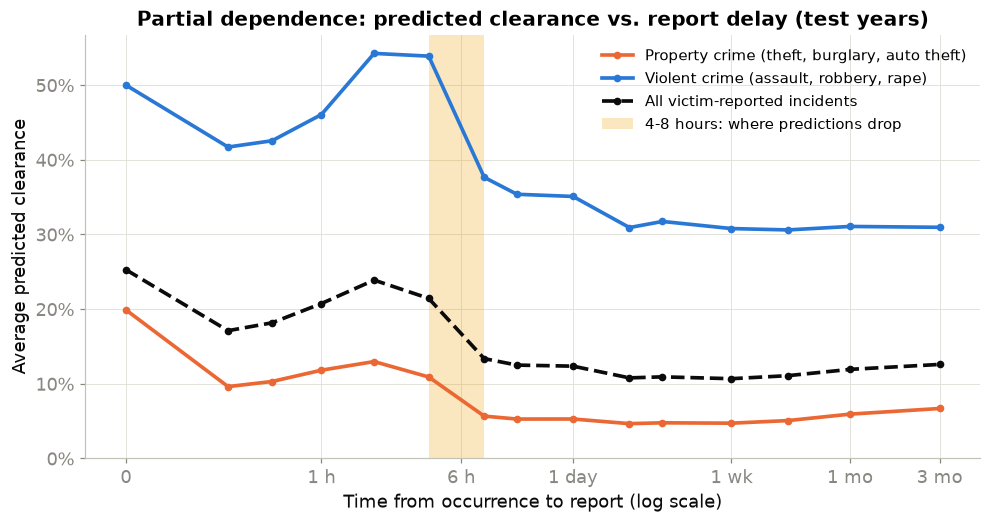

,"Property crime (theft, burglary, auto theft)","Violent crime (assault, robbery, rape)",All victim-reported incidents
0.00 h,0.199,0.500,0.253
0.25 h,0.096,0.417,0.171
0.50 h,0.103,0.425,0.182
1.00 h,0.118,0.460,0.207
2.00 h,0.130,0.542,0.239
4.00 h,0.109,0.539,0.214
8.00 h,0.057,0.376,0.134
12.00 h,0.053,0.354,0.125
24.00 h,0.053,0.351,0.124
48.00 h,0.047,0.309,0.108


In [27]:
PROPERTY = {"Theft", "Burglary", "Auto Theft"}; VIOLENT = {"Aggravated Assault", "Robbery", "Rape", "Murder"}
grid = np.log10(1 + np.array([0, 0.25, 0.5, 1, 2, 4, 8, 12, 24, 48, 72, 24*7, 24*14, 24*30, 24*90]))
def pdp(frame, n=15_000):
    s = tree_X(frame.sample(min(n, len(frame)), random_state=SEED))
    out = []
    for gval in grid:
        s["log_delay"] = gval
        out.append(gb_final.predict_proba(s)[:, 1].mean())
    return np.array(out)
groups = {
    "Property crime (theft, burglary, auto theft)": test[test["category_description"].isin(PROPERTY)],
    "Violent crime (assault, robbery, rape)": test[test["category_description"].isin(VIOLENT)],
    "All victim-reported incidents": test,
}
pd_curves = {k: pdp(v) for k, v in groups.items()}
hours = 10 ** grid - 1
fig, ax = plt.subplots(figsize=(10.5, 5))
for (k, c), col in zip(pd_curves.items(), [ORANGE, BLUE, INK]):
    ax.plot(hours + 0.1, c, color=col, lw=2.4, marker="o", ms=4, label=k, ls="--" if col == INK else "-")
ax.set_xscale("log")
ticks = [0, 1, 6, 24, 24*7, 24*30, 24*90]
ax.set_xticks([t + 0.1 for t in ticks]); ax.set_xticklabels(["0", "1 h", "6 h", "1 day", "1 wk", "1 mo", "3 mo"])
ax.xaxis.set_minor_locator(mtick.NullLocator())
ax.yaxis.set_major_formatter(pct); ax.set_ylim(0)
ax.axvspan(4.1, 8.1, color=YELLOW, alpha=0.25, lw=0, label="4-8 hours: where predictions drop")
ax.set(title="Partial dependence: predicted clearance vs. report delay (test years)",
       xlabel="Time from occurrence to report (log scale)", ylabel="Average predicted clearance")
ax.legend(loc="upper right", fontsize=10)
savefig("f8_delay_pdp"); plt.show()
pd.DataFrame(pd_curves, index=[f"{h:.2f} h" for h in hours]).round(3)

### What the interpretation tells us
- **Offense dominates** (PR-AUC drops 0.28 when it's shuffled). That's expected: the crime type sets the starting odds.
- **Reporting delay is the clear second factor** (a 0.095 drop), more than location, neighborhood and time of day combined. Holding the offense fixed, a 10× longer delay cuts the odds of clearance to **0.60×**.
- **The shape matters more than the slope.** Two features of the partial-dependence curve stand out:
  1. A delay of **exactly zero** is 44% of reports and has the highest predicted clearance. These are mostly cases written up on the spot, such as shoplifters held by store staff or an officer at the scene. So a "0" partly records *how* the case reached police, not just how fast.
  2. After that, predictions stay roughly flat for the first ~4 hours, then **drop sharply between 4 and 8 hours**, and level off after a day. For property crime the drop is from ~11% to ~6% (about half); for violent crime, from ~54% to ~38% (about 30%).
  
  For stakeholders, the useful window is *the same few hours*, not the first minutes. Public guidance should say "report within hours, not tomorrow." Online reporting systems that take days to be reviewed lose that window.
- **No witness (time rounded to :00):** odds of 0.69× at the same offense *and* delay, but low permutation importance (0.008), because most of what it signals the model already learns from delay. That supports H2 as a real but modest independent signal.
- **Family violence:** odds of **2.89×** within the same offense. Victims usually know who the suspect is, so identification, the hardest step in most investigations, is already done.
- **Neighborhood adds little** once offense and delay are known (PC1 importance 0.011; sector and district below 0.004). This is reassuring for fairness: the model isn't mainly keying on *where* the victim lives. It still needs an audit before any real use (Section 6).
- **Date on the 1st** has no effect in the boosted model. A future version can drop it.

## 5. Summary for the presentation

In [28]:
print("Scope:", f"{len(d):,} victim-reported incidents; {len(arrest_generated)} arrest-generated offenses removed")
print("Best hyperparameters: LR C =", best_C, "| RF (depth, min_leaf) =", best_rf, "| GBM (lr, leaves) =", best_gb, f"trees={gb_final.n_iter_}")
print(test_table.round(3).to_string())
print(split_cmp.round(3).to_string())

Scope: 1,423,384 victim-reported incidents; 39 arrest-generated offenses removed
Best hyperparameters: LR C = 10.0 | RF (depth, min_leaf) = (None, 5) | GBM (lr, leaves) = (0.05, 31) trees=1315
                       PR-AUC  ROC-AUC  Brier  Top-20% capture  Within-offense AUC
Offense-only baseline   0.446    0.817  0.111            0.562               0.500
Logistic regression     0.521    0.865  0.100            0.649               0.727
Random forest           0.552    0.869  0.097            0.646               0.731
Gradient boosting       0.565    0.879  0.094            0.671               0.735
                          PR-AUC  ROC-AUC  Base rate
Random 80/20 split         0.697    0.895      0.182
Train past, test 2022-25   0.565    0.879      0.163


## 6. Discussion

**Key takeaways**
1. Whether a case gets solved is mostly decided by **what the crime is and how it reached police**: how fast it was reported, whether anyone saw it happen, and whether the victim knows the suspect.
2. A model at intake can rank cases usefully. The top 20% of cases contain 67% of eventual clearances, and it ranks well *within* an offense.
3. **Evaluate on the future.** Shuffled years overstate performance, and probabilities drift as clearance practice changes (H3).

**Limitations**
- **The label is a police outcome, not ground truth.** "Cleared" includes exceptional clearances, and recording conventions (a zero delay, rounded times) are themselves features. Part of what the model learns is how APD records cases.
- **The associations aren't causal.** Late reports may differ in other ways: less evidence, no suspect description. We can say late reports are cleared less often, not that reporting faster would make *a given* case solvable.
- **Feedback-loop risk.** If predictions were used to decide which cases get investigated, low-scored cases would get less effort and be solved even less often, which the next model would learn. Property crimes and quieter residential areas would be most affected. Any use should audit errors and effort by district first, and treat the score as one input, never as an automatic screen-out.
- **Drift:** the model needs regular recalibration (2022 predictions were about 4 points too high).
- **Compute shortcuts:** we tuned on a 400k sample with small grids, and the random forest was refit on 600k rows. A larger search could add a little performance, but not change the conclusions: validation scores across settings were within ±0.01.